# CS1 - Full Formation Evaluation of a North Sea Discovery Well (30/6-5)

**Petrophys Case Studies - Project 1**

This is not a single-module tutorial. It is a realistic, end-to-end *interpretation project*
with a concrete deliverable: a complete formation evaluation of a discovery well and a
zone-by-zone recommendation of **where to perforate**.

We follow the standard case-study spine:

1. **The brief** - the business question and why it matters.
2. **The well and data** - what we have, what is missing.
3. **Workflow plan** - the chain of interpretation steps and why in this order.
4. **Execution** - the dynamic workflow run, with its step trace shown as an audit.
5. **Integrated result** - a multi-track interpretation plot and a per-formation results table.
6. **Interpretation and deliverable** - what the numbers mean, and the ranked completion picks.
7. **Limitations and assumptions** - honest caveats.
8. **Appendix** - how to re-run on another well.

> This notebook *uses* the library end-to-end and references the Part A / Part B tutorials for
> the underlying physics (Vcl from GR, density-neutron porosity, Archie saturation, net-pay
> cutoffs). It does not re-teach those basics.

## Part 1 - The brief

> **From:** Subsurface team lead, North Sea development asset.
> **Subject:** Well 30/6-5 - full formation evaluation and completion recommendation.
>
> We have just finished logging discovery well **30/6-5** (Oseberg area, Norwegian North Sea).
> Wireline is in. Before we design the completion, I need a **defensible, auditable formation
> evaluation** of the whole logged section and a **ranked list of intervals to perforate**.
> Tell me which zones are pay, how good they are (porosity, water saturation, permeability),
> and where you would put the guns first. Flag anything you had to assume.

**Why it matters.** The completion decision commits real money. Perforate the wrong zone and you
produce water or nothing; miss a good zone and you leave reserves behind. The recommendation has
to be traceable - every cutoff and every assumed parameter must be visible so the reservoir
engineer can challenge it. That auditability is exactly what the *dynamic workflow* trace gives us.

**The deliverable (three artifacts):**

- **(a)** a multi-track interpretation / log plot summarizing the evaluation;
- **(b)** a per-formation results table (net pay, average PHIE, average Sw, hydrocarbon pore
  thickness);
- **(c)** a ranked list of candidate completion intervals with written rationale.

## Part 2 - The well and the data

**Well 30/6-5** is a Geolink clastic well from the Oseberg area, logged in **metres**. It penetrates
the full Norwegian North Sea Jurassic stratigraphy - from the shallow Nordland shales down through
the Brent-equivalent **Baat Group** (Ness / Etive sands) and into the **Statfjord Formation** near
total depth.

What we have and what we are missing drives every modelling choice below, so we inventory it first.

In [1]:
%matplotlib inline
import warnings
warnings.filterwarnings("ignore")

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import petrophys
from petrophys.io import read_las
from petrophys.qaqc.standardization import standardize_curves
from petrophys.data import DATA_DIR

print("petrophys", petrophys.__version__)

def ascii_safe(s):
    # 30/6-5 header field name has mojibake; keep console output ASCII-only.
    return str(s).encode("ascii", "replace").decode("ascii")

# --- Load the raw LAS and standardize curve names / units --------------------
las_path = petrophys.sample("30_6-5")
well = read_las(las_path)
well = standardize_curves(well, rename_curves=True, convert_units=True)

print("Well name      :", well.name)
print("Field          :", ascii_safe(well.header.field))
print("Depth interval :", round(well.start_depth, 1), "-", round(well.stop_depth, 1),
      well.depth_unit)
print("Samples        :", well.n_samples, "at step", round(well.step, 4), well.depth_unit)
print("Curves         :", ", ".join(well.curves))

petrophys 0.1.0


Well name      : 30/6-5
Field          : OSEBERG ??ST
Depth interval : 176.6 - 3556.1 m
Samples        : 22176 at step 0.1524 m
Curves         : LITHOLOGY_GEOLINK, CALI, DRHO, NPHI, RHOB, PEF, GR, DTC, DTE, RDEP, SP, RSHA, RMED, BS, PHIC, GDEN, KH_CORE, KV_CORE, SWC, SOC


### Data readiness check

We split the available curves into the log families the interpretation needs, and note the gaps.
The two most consequential gaps for 30/6-5 are: **(i)** there is no bottom-hole temperature (BHT)
and no formation-water resistivity (Rw) in the header, and **(ii)** the photoelectric factor (PEF),
which helps discriminate lithology, is only recorded over a narrow deep interval. Both facts are
flagged here and revisited in Part 7.

In [2]:
families = {
    "Gamma ray / clay":   ["GR", "SP"],
    "Porosity (D/N/S)":   ["RHOB", "NPHI", "DTC"],
    "Resistivity":        ["RDEP", "RMED", "RSHA"],
    "Lithology aids":     ["PEF", "DRHO", "LITHOLOGY_GEOLINK"],
    "Borehole / caliper": ["CALI", "BS"],
    "Core":               ["PHIC", "KH_CORE", "SWC", "SOC"],
}
for fam, mnems in families.items():
    present = [m for m in mnems if well.has_curve(m)]
    missing = [m for m in mnems if not well.has_curve(m)]
    print("{:22s} present: {:35s} missing: {}".format(
        fam, ", ".join(present) if present else "-",
        ", ".join(missing) if missing else "-"))

print()
# PEF live interval - it is only recorded over the deep section.
pef = well.get("PEF").data
depth = well.depth
pef_live = depth[np.isfinite(pef)]
print("PEF live interval : {:.0f} - {:.0f} m (of {:.0f} - {:.0f} m logged)".format(
    pef_live.min(), pef_live.max(), depth.min(), depth.max()))

print("Header BHT        :", well.header.bht, "(missing -> must assume)")
print("Header Rw / Rmf   :", getattr(well.header, "rw", None), "/", well.header.rmf,
      "(missing -> must assume)")

Gamma ray / clay       present: GR, SP                              missing: -
Porosity (D/N/S)       present: RHOB, NPHI, DTC                     missing: -
Resistivity            present: RDEP, RMED, RSHA                    missing: -
Lithology aids         present: PEF, DRHO, LITHOLOGY_GEOLINK        missing: -
Borehole / caliper     present: CALI, BS                            missing: -
Core                   present: PHIC, KH_CORE, SWC, SOC             missing: -

PEF live interval : 2790 - 3176 m (of 177 - 3556 m logged)
Header BHT        : None (missing -> must assume)
Header Rw / Rmf   : None / None (missing -> must assume)


## Part 3 - The workflow plan

We use the library's **dynamic workflow** (`run_dynamic_workflow`) as the interpretation backbone.
The dynamic workflow inspects the curves that are present and runs only the modules it can support,
in the correct petrophysical order, recording a **step-by-step trace** we will use as the audit.

The chain it will execute for 30/6-5 (each step references the tutorial that teaches it):

| # | Step | What it does | Key inputs |
|---|------|--------------|-----------|
| 1 | Temperature | Builds a T profile from surface T and BHT (assumed here) | depth, BHT |
| 2 | Bad-hole | Flags washed-out / rugose hole from CALI vs BS | CALI, BS, DRHO |
| 3 | Vcl | Volume of clay from GR (and SP) | GR, SP |
| 4 | Porosity | Density-neutron total porosity PHIT and effective PHIE | RHOB, NPHI |
| 5 | Lithology | Multi-mineral solve (quartz / calcite / dolomite / clay) | RHOB, NPHI, PEF |
| 6 | Core correction | Ties log porosity/perm to core (PHIC, KH_CORE) | PHIC, KH_CORE |
| 7 | Rw | Formation-water resistivity (assumed Rw, temp-corrected) | assumed Rw + T |
| 8 | Saturation | Water saturation Sw (Archie family, auto-routed) | RDEP, PHIE, Rw |
| 9 | Permeability | Log permeability, core-calibrated where possible | PHIE, core |
| 10 | Rock quality | RQI / FZI flow indicators | PHIE, PERM |
| 11 | Net pay | 3-stage cutoffs -> net rock / net reservoir / net pay | Vcl, PHIE, Sw |

We then load the **formation tops** and roll the sample-by-sample answer up to a
**per-formation** summary, and finally turn that into a completion recommendation.

**Model choices and why:**

- **Lithology = clastic, matrix = sandstone.** 30/6-5 is a siliciclastic Jurassic section; the
  reservoirs are the Brent-equivalent and Statfjord sands.
- **Saturation model = auto.** We let the workflow route to the appropriate Archie-family model.
  Case study CS5 does a dedicated Sw-model sensitivity; here we take the workflow's routed answer.
- **Assumed Rw and BHT (flagged).** 30/6-5 has no measured Rw or BHT, so we supply explicit
  assumptions consistent with a moderately saline North Sea Jurassic aquifer, and we carry those
  assumptions into the limitations section. These are the single biggest lever on Sw.

### Assumed parameters (explicit, because the header has none)

We set these **before** the run so they appear in the configuration and in the trace. Every value
below is an *assumption*, not a measurement, and is revisited in Part 7.

In [3]:
from petrophys.workflow import run_dynamic_workflow, DynamicWorkflowConfig

# --- ASSUMED environment (30/6-5 header carries NO BHT / Rw / Rmf) -----------
ASSUMED = {
    "surface_temp_f": 50.0,    # ~10 C North Sea seabed/surface reference
    "bht_f":          230.0,   # ~110 C assumed bottom-hole temp at TD
    "td_ft":          11667.0, # 3556 m TD expressed in ft for the T gradient
    "rw":             0.03,    # assumed formation-water resistivity (ohm.m)
    "rw_meas_temp_f": 230.0,   # Rw quoted at reservoir temperature
}
# --- Interpretation cutoffs (net-pay definition) -----------------------------
CUTOFFS = {
    "vcl_cutoff":  0.40,   # clay-volume ceiling for reservoir rock
    "sw_cutoff":   0.60,   # water-saturation ceiling for pay
    "phie_cutoff": 0.08,   # effective-porosity floor for pay
}

config = DynamicWorkflowConfig(
    lithology="clastic",
    matrix_type="sandstone",
    **ASSUMED,
    **CUTOFFS,
)

print("Assumed environment:")
for k, v in ASSUMED.items():
    print("   {:16s} = {}".format(k, v))
print("Net-pay cutoffs:")
for k, v in CUTOFFS.items():
    print("   {:16s} = {}".format(k, v))

Assumed environment:
   surface_temp_f   = 50.0
   bht_f            = 230.0
   td_ft            = 11667.0
   rw               = 0.03
   rw_meas_temp_f   = 230.0
Net-pay cutoffs:
   vcl_cutoff       = 0.4
   sw_cutoff        = 0.6
   phie_cutoff      = 0.08


## Part 4 - Execution: run the dynamic workflow and read its audit trace

One call runs the whole chain. The returned `DynamicWorkflowResult` records which steps executed,
which were skipped (and why), the computed Rw, and a full per-step trace. We treat that trace as the
**interpretation audit** - it is what makes the recommendation defensible.

In [4]:
result = run_dynamic_workflow(well, config=config)

print("Overall success :", result.success)
print("Steps executed  :", len(result.steps_executed))
print("Steps skipped   :", ", ".join(result.steps_skipped) if result.steps_skipped else "none")

rw_arr = np.asarray(result.rw_computed, dtype=float)
rw_mean = float(np.nanmean(rw_arr)) if rw_arr.size else float("nan")
print("Rw (computed)   : {:.4f} ohm.m (temperature-corrected from assumed {} ohm.m)".format(
    rw_mean, ASSUMED["rw"]))

Overall success : True
Steps executed  : 15
Steps skipped   : rmf, hc_correction, porosity_refinement
Rw (computed)   : 0.0532 ohm.m (temperature-corrected from assumed 0.03 ohm.m)


### The step-by-step audit

Below we render each executed step with its method, the curves it consumed, the curves it produced,
and the decisions it logged. Read this top-to-bottom: it is the paper trail from raw logs to net pay.

In [5]:
for sr in result.steps_executed:
    status = "OK " if sr.success else "FAIL"
    print("[{}] {}".format(status, sr.step))
    if sr.method:
        print("       method : {}".format(sr.method))
    if sr.input_curves:
        print("       inputs : {}".format(", ".join(sr.input_curves)))
    if sr.output_curves:
        print("       outputs: {}".format(", ".join(sr.output_curves)))
    for d in sr.decisions[:4]:
        print("       -> {}".format(ascii_safe(d)))
    if not sr.success and sr.message:
        print("       ERROR: {}".format(ascii_safe(sr.message)))


[OK ] temperature
       method : linear_gradient_from_BHT
       outputs: TEMP
       -> Temperature profile anchored to BHT metadata/input
       -> Gradient = 1.5428 F/100ft (28.12 C/km)
       -> Temp range: 58.9 - 230.0 F
[OK ] bad_hole
       method : caliper_drho_flags
       inputs : CALI, BS, DRHO, RHOB, PEF
       outputs: BAD_HOLE
       -> 12631 bad-hole samples flagged out of 22176
[OK ] vclay
       method : linear
       inputs : GR, SP, NPHI, RHOB
       outputs: VCL, VCLAY, VCL_GR, VCLGR, VCL_SP, VCLSP, VCL_ND, VCLND
       -> GR_min = 21.6 (auto, P5 of GR)
       -> GR_max = 115.3 (auto, P95 of GR)
       -> GR method: linear
       -> SP method: enabled
[OK ] rcl
       method : lithology_shale_median_rt
       inputs : RDEP, VCL
       -> Rcl = 2.91 ohm.m (median RT in shale lithology samples, n=1172)
[OK ] porosity
       method : component_based
       inputs : NPHI, RHOB, DTC, VCL
       outputs: PHIN, PHID, PHIS, PHIT, PHIE, PHI_SEC
       -> Initial porosity pa

The same trace is available as a tidy DataFrame (handy for exporting an audit sheet).

In [6]:
trace_df = result.to_dataframe()
trace_df[["Step", "Status", "Method", "Input Curves", "Output Curves"]]

,Step,Status,Method,Input Curves,Output Curves
0,temperature,OK,linear_gradient_from_BHT,,TEMP
1,bad_hole,OK,caliper_drho_flags,"CALI, BS, DRHO, RHOB, PEF",BAD_HOLE
2,vclay,OK,linear,"GR, SP, NPHI, RHOB","VCL, VCLAY, VCL_GR, VCLGR, VCL_SP, VCLSP, VCL_..."
3,rcl,OK,lithology_shale_median_rt,"RDEP, VCL",
4,porosity,OK,component_based,"NPHI, RHOB, DTC, VCL","PHIN, PHID, PHIS, PHIT, PHIE, PHI_SEC"
5,lithology,OK,multi_mineral_solver,"RHOB, VCL, NPHI, PHIE, PEF, DTC","VQUAR, VCALC, VDOLO, VANHY, MMQC"
6,core_correction,OK,same_well_core_correction,PHIE,"PHIE_CC, PERM_CC"
7,rw,OK,user_provided_temperature_profile_corrected,,RW
8,invasion,OK,rxo_rt_ratio,"RDEP, RSHA+RMED",INVASION_RATIO
9,saturation,OK,archie+indonesia+dual_water,"RDEP, PHIE_CC, VCL","SW, SXO"


### QC decision: not every flagged sample is real pay

The workflow wrote `NET_PAY`, `PHIE`, `SW` and `PERM` onto the well. Before we trust the numbers we
sanity-check *where* the net-pay flag fired. A quick depth histogram exposes a classic pitfall:
shallow, unconsolidated, washed-out shales can pass a naive porosity cutoff and masquerade as pay.

In [7]:
depth = well.depth
netpay = well.get("NET_PAY").data
pay_depths = depth[netpay > 0.5]

print("Total net-pay samples flagged:", pay_depths.size)
print("Distribution by depth (200 m bins):")
for lo in range(600, 3600, 200):
    n = int(np.sum((pay_depths >= lo) & (pay_depths < lo + 200)))
    if n:
        bar = "#" * min(60, n // 12)
        print("  {:4d}-{:4d} m : {:4d}  {}".format(lo, lo + 200, n, bar))

Total net-pay samples flagged: 1985
Distribution by depth (200 m bins):
   800-1000 m :  160  #############
  1000-1200 m :  734  ############################################################
  1200-1400 m :  302  #########################
  1400-1600 m :    6  
  2000-2200 m :    2  
  2200-2400 m :    2  
  2800-3000 m :  333  ###########################
  3000-3200 m :    6  
  3200-3400 m :  346  ############################
  3400-3600 m :   94  #######


Two things jump out:

- A large block of "pay" between **~950 and 1400 m**. That sits inside the shallow **Hordaland /
  Nordland** shale section - far above any Jurassic reservoir. It is a **data artifact**: soft,
  washed-out shallow shale reads high apparent porosity and low resistivity, and slips through the
  cutoffs. We will *exclude* it from the completion recommendation and call it out as a limitation.
- Two genuine, deep sand packages: **~2840-2960 m** (Baat Group: Ness / Etive) and
  **~3220-3550 m** (Statfjord). These are the real targets.

This is exactly why we roll up **by named formation** next, rather than trusting a single field-wide
net-pay total.

## Part 5 - Integrated result

### 5a. Per-formation roll-up

We load the geological tops from `formations_30_6-5.csv` and roll the sample-by-sample interpretation
up to a per-formation summary with `analyze_formations`. This produces net pay, NTG, average PHIE /
Sw / Vcl / permeability, and a hydrocarbon-pore-thickness index (HCPV) for each formation.

In [8]:
from petrophys.summation.formation_analysis import load_formations_csv, analyze_formations

tops_csv = os.path.join(DATA_DIR, "formations_30_6-5.csv")
formations = load_formations_csv(tops_csv)
print("Loaded {} formation intervals from {}".format(len(formations), os.path.basename(tops_csv)))

fa = analyze_formations(well, formations)
fa_df = fa.to_dataframe()

# Deliverable (b): compact per-formation results table.
cols = ["Formation", "Top", "Bottom", "Net Pay (m)", "NTG",
        "Avg PHIE", "Avg Sw", "Avg Perm (mD)", "HCPV"]
table = fa_df[cols].copy()
table = table.round({"Net Pay (m)": 1, "NTG": 3, "Avg PHIE": 3,
                     "Avg Sw": 3, "Avg Perm (mD)": 1, "HCPV": 2})
table

Loaded 20 formation intervals from formations_30_6-5.csv


,Formation,Top,Bottom,Net Pay (m),NTG,Avg PHIE,Avg Sw,Avg Perm (mD),HCPV
0,NORDLAND GP.,181.0,726.0,0.0,0.000,NaN,NaN,NaN,NaN
1,Utsira Fm.,726.0,879.0,0.0,0.000,NaN,NaN,NaN,NaN
2,HORDALAND GP.,879.0,1908.0,183.2,0.178,0.431,0.551,9996.9,35.43
3,ROGALAND GP.,1908.0,2203.0,0.3,0.001,0.354,0.507,10000.0,0.05
4,Balder Fm.,1908.0,2023.0,0.0,0.000,NaN,NaN,NaN,NaN
5,Sele Fm.,2023.0,2123.0,0.0,0.000,NaN,NaN,NaN,NaN
6,Lista Fm.,2123.0,2203.0,0.3,0.004,0.354,0.507,10000.0,0.05
7,SHETLAND GP.,2203.0,2408.0,0.3,0.001,0.336,0.521,9211.2,0.05
8,CROMER KNOLL GP.,2408.0,2452.0,0.0,0.000,NaN,NaN,NaN,NaN
9,VIKING GP.,2452.0,2841.0,0.8,0.002,0.254,0.469,4189.5,0.10


The CSV nests **group** intervals (e.g. `BAAT GP.`) around their **member** formations
(`Ness Fm.`, `Etive Fm.`), so those depths overlap and would double-count. For the reservoir story we
keep only the members (and standalone formations) that actually carry net pay, and drop the barren
and the artifactual-shallow rows. HCPV here is a **hydrocarbon pore thickness** = avg_PHIE x (1 - avg_Sw)
x net_pay, i.e. metres of net hydrocarbon-filled porosity per unit area - a screening volume proxy.

In [9]:
# Named Jurassic reservoir members we care about (exclude parent groups + shallow artifact).
RESERVOIR_MEMBERS = ["Ness Fm.", "Etive Fm.", "Cook Fm.", "Statfjord Fm."]

res_rows = fa_df[fa_df["Formation"].isin(RESERVOIR_MEMBERS)].copy()
res_rows = res_rows[res_rows["Net Pay (m)"] > 0.5].copy()
res_rows = res_rows.sort_values("HCPV", ascending=False)

show = res_rows[cols].round({"Net Pay (m)": 1, "NTG": 3, "Avg PHIE": 3,
                             "Avg Sw": 3, "Avg Perm (mD)": 1, "HCPV": 2})
print("Reservoir formations carrying net pay (ranked by hydrocarbon pore thickness):")
print(show.to_string(index=False))
print()
print("Field-wide (all overlapping intervals) total net pay : {:.1f} m".format(fa.total_net_pay))
print("Reservoir-member net pay (no double count)           : {:.1f} m".format(
    res_rows["Net Pay (m)"].sum()))

Reservoir formations carrying net pay (ranked by hydrocarbon pore thickness):
    Formation    Top  Bottom  Net Pay (m)   NTG  Avg PHIE  Avg Sw  Avg Perm (mD)  HCPV
    Etive Fm. 2865.0  2958.0         41.0 0.441     0.198   0.315         1399.9  5.55
Statfjord Fm. 3223.0  3556.0         67.1 0.201     0.133   0.520          263.1  4.29
     Ness Fm. 2841.0  2865.0          9.0 0.373     0.182   0.415          991.9  0.96
     Cook Fm. 3071.0  3123.0          0.9 0.018     0.105   0.567          122.1  0.04

Field-wide (all overlapping intervals) total net pay : 354.5 m
Reservoir-member net pay (no double count)           : 118.0 m


### 5b. Deliverable (a): the multi-track interpretation plot

We assemble a standard composite interpretation display over the reservoir section
(**~2750-3560 m**), the interval where PEF is live and both real sand packages sit:

- **Track 1** - GR with the computed clay volume (Vcl).
- **Track 2** - deep and medium resistivity (log scale).
- **Track 3** - effective porosity PHIE and water saturation Sw (Sw increasing to the left).
- **Track 4** - net-pay flag, shaded, with formation tops annotated.

Green shading in track 4 marks the perforation candidates.

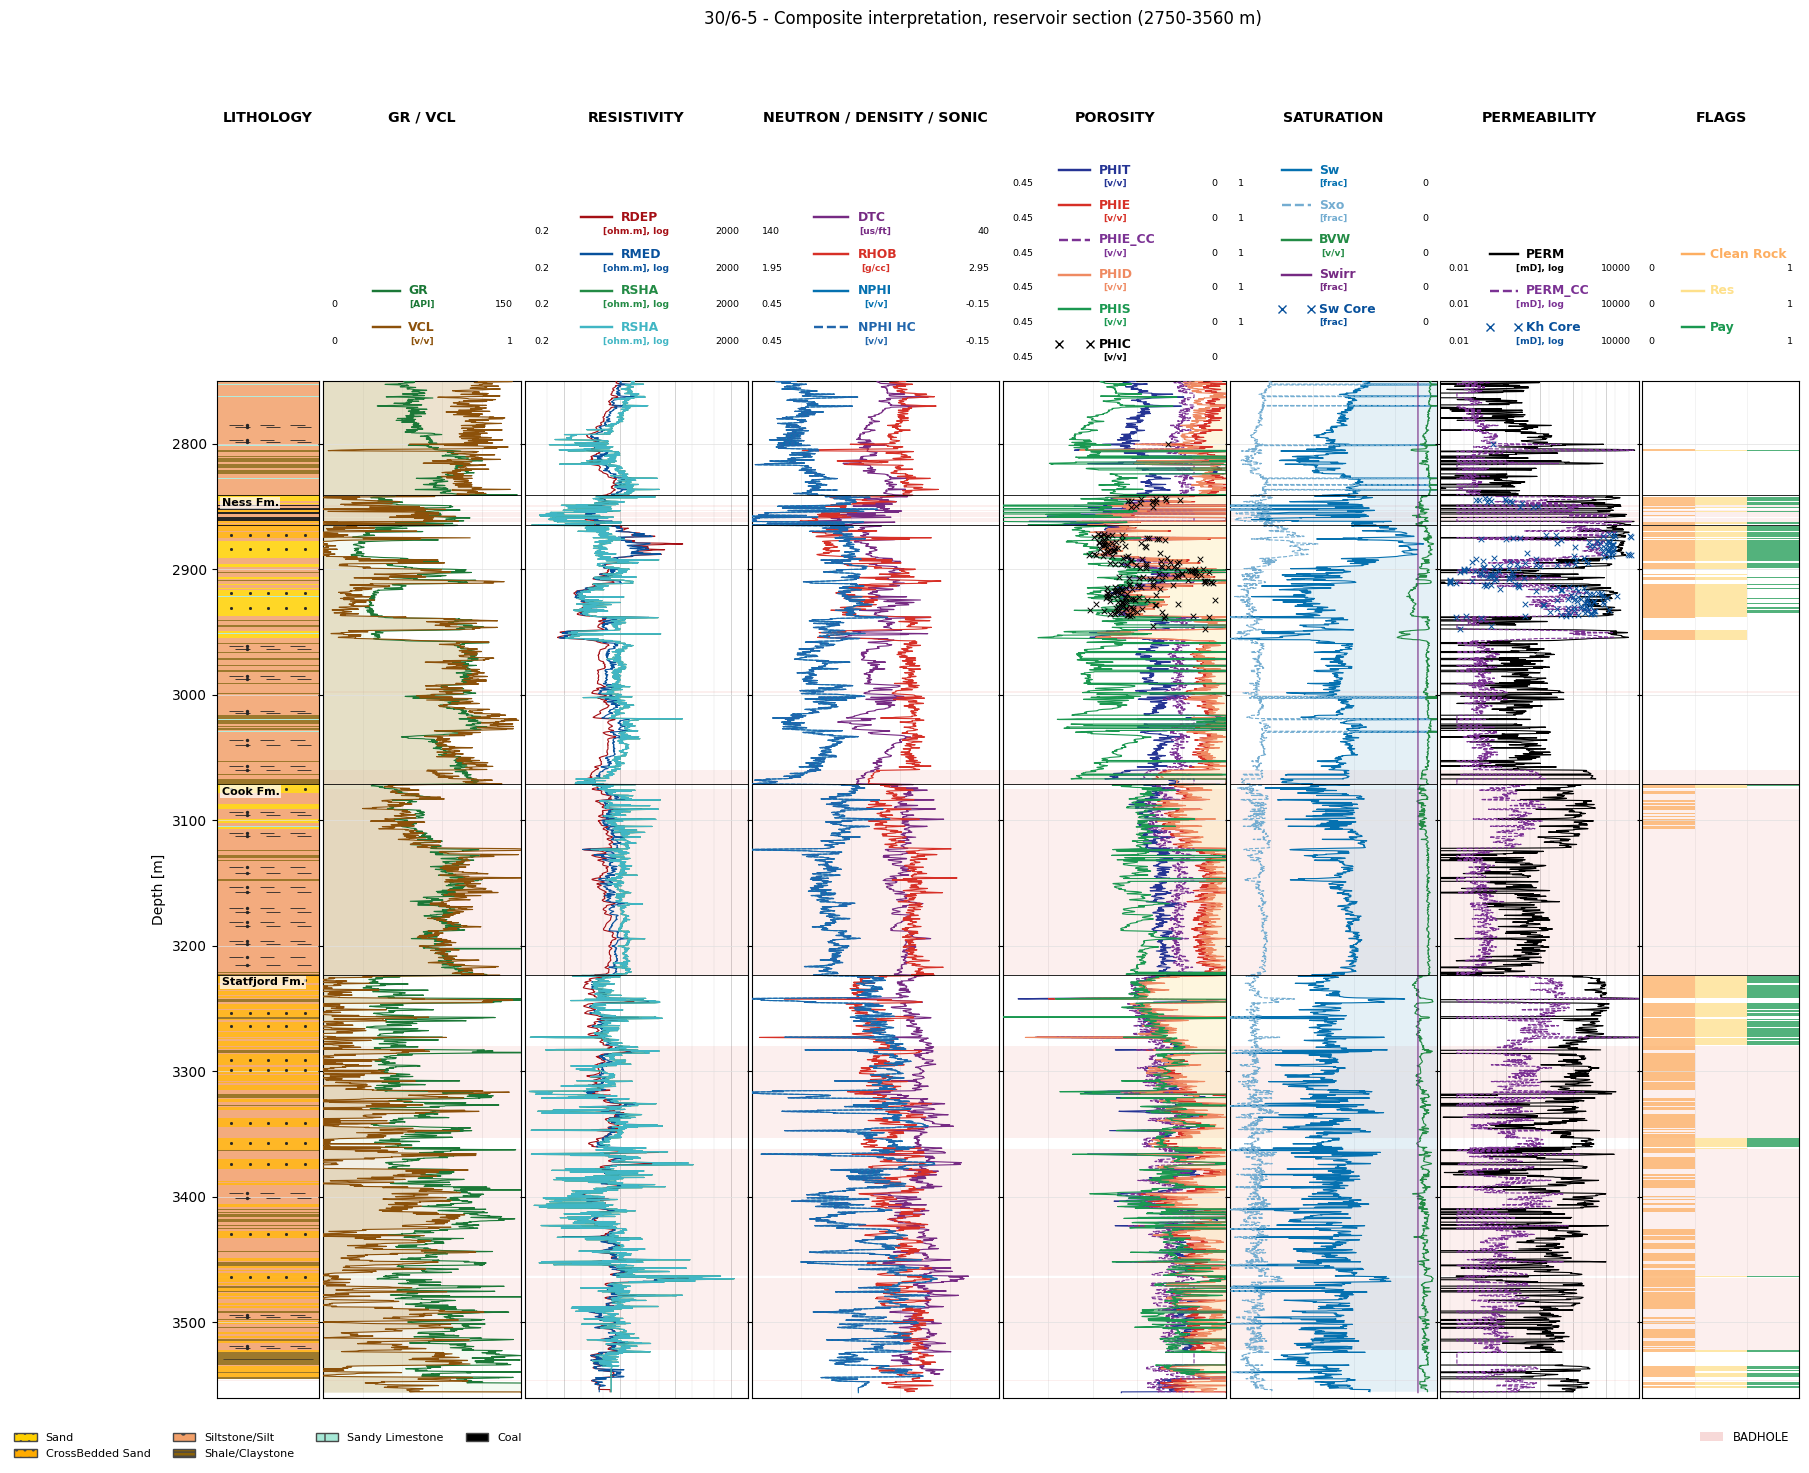

In [10]:
from petrophys.visualization import create_log_viewer

TOP, BOT = 2750.0, 3560.0

# Deliverable (a): render the composite interpretation display with the library's
# template-driven log viewer. The "petrophysics" template lays out the standard
# interpretation tracks (GR/Vcl, resistivity on log scale, PHIE/Sw, and the
# NET_ROCK/NET_RES/NET_PAY flag tracks) directly from the curves the workflow
# wrote onto the well. Formation tops are passed as a {name: depth} map so the
# reservoir members and the Baat Gp. top are annotated automatically.
tops = {
    fm.name: fm.top_depth
    for fm in formations
    if TOP <= fm.top_depth <= BOT and fm.name in RESERVOIR_MEMBERS + ["BAAT GP."]
}

viewer = create_log_viewer(
    well,
    template_defaults="petrophysics",
    depth_range=(TOP, BOT),
    formation_tops=tops,
)
viewer.fig.suptitle(
    "30/6-5 - Composite interpretation, reservoir section (2750-3560 m)",
    y=1.002, fontsize=12,
)
plt.show()

## Part 6 - Interpretation and the deliverable

### What the numbers mean

Reading the table and the plot together, 30/6-5 has **two viable reservoir packages**, and they are
qualitatively different:

- **Baat Group - Ness / Etive sands (~2841-2958 m).** Clean, blocky sand: low Vcl, effective
  porosity around **19-20 pu**, water saturation as low as **~31-41%**, and the highest permeability
  of the reservoir units (hundreds to >1000 mD). This is a strong oil-bearing package - low Sw, good
  storage, good deliverability. It is the **primary target**.
- **Statfjord Formation (~3223-3556 m).** A thick gross sand with the **most net pay (~67 m)**, but
  it is deeper and tighter: PHIE ~**13 pu**, permeability a few hundred mD, and higher water
  saturation (~**52%**). Still pay, but poorer quality and closer to the Sw cutoff, so more
  water-risk. A solid **secondary target**.
- **Cook Formation (~3071-3123 m)** contributes only a thin, tight, high-Sw sliver of pay - not a
  standalone completion target.

The shallow "pay" flagged between ~950 and 1400 m is **not** a target: it is soft shallow shale in a
washed-out hole and is excluded (see Part 7).

### Deliverable (c): ranked candidate completion intervals

We build the ranking directly from the per-formation roll-up, scoring each pay-bearing reservoir
member by hydrocarbon pore thickness (the volume proxy), then by porosity, permeability and Sw
margin. The output is an ordered perforation plan with written rationale.

In [11]:
ranking = res_rows.copy()
ranking = ranking.sort_values("HCPV", ascending=False).reset_index(drop=True)

rationale = {
    "Ness Fm.":      "Baat Gp. sand, low Sw and high perm - part of the primary Brent target.",
    "Etive Fm.":     "Clean blocky Baat Gp. sand, lowest Sw and good perm - the primary target.",
    "Statfjord Fm.": "Thickest net pay but deeper, tighter and higher Sw - secondary target.",
    "Cook Fm.":      "Thin, tight, high-Sw sliver - marginal; not a standalone completion.",
}

print("=" * 92)
print("30/6-5  RANKED COMPLETION CANDIDATES  (perforate top-down)")
print("=" * 92)
print("{:<3s} {:<14s} {:>13s} {:>8s} {:>7s} {:>7s} {:>9s} {:>7s}".format(
    "#", "Formation", "Interval(m)", "NetPay", "PHIE", "Sw", "Perm", "HCPV"))
print("-" * 92)
for i, row in ranking.iterrows():
    print("{:<3d} {:<14s} {:>6.0f}-{:<6.0f} {:>8.1f} {:>7.3f} {:>7.3f} {:>9.1f} {:>7.2f}".format(
        i + 1, row["Formation"], row["Top"], row["Bottom"], row["Net Pay (m)"],
        row["Avg PHIE"], row["Avg Sw"], row["Avg Perm (mD)"], row["HCPV"]))
print("-" * 92)
print()
print("RATIONALE")
for i, row in ranking.iterrows():
    print("  {}. {:<14s} {}".format(i + 1, row["Formation"],
                                     rationale.get(row["Formation"], "")))
print()
# Primary target = the Baat Group Brent sands (Ness + Etive together).
baat = ranking[ranking["Formation"].isin(["Ness Fm.", "Etive Fm."])]
statf = ranking[ranking["Formation"] == "Statfjord Fm."]
print("PRIMARY RECOMMENDATION: perforate the Baat Gp. Brent sands first "
      "(Ness + Etive, {:.0f}-{:.0f} m) - clean, low-Sw, high-perm oil sand.".format(
          baat["Top"].min(), baat["Bottom"].max()))
if not statf.empty:
    print("Then evaluate the deeper Statfjord Fm. ({:.0f}-{:.0f} m) as a secondary / step-out "
          "target - most gross pay but tighter and higher Sw.".format(
              statf["Top"].iloc[0], statf["Bottom"].iloc[0]))

30/6-5  RANKED COMPLETION CANDIDATES  (perforate top-down)
#   Formation        Interval(m)   NetPay    PHIE      Sw      Perm    HCPV
--------------------------------------------------------------------------------------------
1   Etive Fm.        2865-2958       41.0   0.198   0.315    1399.9    5.55
2   Statfjord Fm.    3223-3556       67.1   0.133   0.520     263.1    4.29
3   Ness Fm.         2841-2865        9.0   0.182   0.415     991.9    0.96
4   Cook Fm.         3071-3123        0.9   0.105   0.567     122.1    0.04
--------------------------------------------------------------------------------------------

RATIONALE
  1. Etive Fm.      Clean blocky Baat Gp. sand, lowest Sw and good perm - the primary target.
  2. Statfjord Fm.  Thickest net pay but deeper, tighter and higher Sw - secondary target.
  3. Ness Fm.       Baat Gp. sand, low Sw and high perm - part of the primary Brent target.
  4. Cook Fm.       Thin, tight, high-Sw sliver - marginal; not a standalone completion

**Recommendation in one line:** the **Baat Group (Ness + Etive, ~2841-2958 m)** is the primary
completion target - clean, low-Sw, high-permeability oil sand; the **Statfjord Formation
(~3223-3556 m)** is the secondary target with the most gross pay but poorer quality and higher water
risk. Cook is marginal. The shallow flagged interval is a data artifact and is not perforated.

## Part 7 - Limitations and assumptions

An interpretation is only as trustworthy as its caveats. The material ones for 30/6-5:

- **Assumed Rw and temperature.** The header has no BHT and no Rw, so we supplied `bht_f=230`,
  `surface_temp_f=50`, and `rw=0.03 ohm.m`. Water saturation scales roughly with `sqrt(Rw)`, so this
  is the single biggest lever on the Sw numbers and hence on which samples clear the `Sw < 0.60`
  cutoff. A dedicated Sw-model / parameter sensitivity is the subject of case study **CS5**.
- **Shallow "pay" is an artifact.** The net-pay flag fires across ~950-1400 m in the shallow
  Hordaland/Nordland shales. This is soft, washed-out formation reading spuriously high apparent
  porosity and low resistivity - not reservoir. We excluded it by restricting the recommendation to
  named Jurassic reservoir members. A stricter Vcl cutoff or a hard depth/formation gate would
  suppress it automatically.
- **PEF only over the deep section.** Lithology discrimination is best where PEF is live
  (~2790-3176 m); above that the multi-mineral solve leans on density-neutron alone. This mainly
  affects the shallow section, which is not a target anyway.
- **Group vs member double counting.** The tops CSV nests groups around their members. We reported
  members-only for the reservoir roll-up to avoid counting the same metres twice.
- **Cutoffs are conventions.** `Vcl < 0.40`, `PHIE > 0.08`, `Sw < 0.60` are reasonable clastic
  defaults but are choices; moving them moves the net-pay totals. They are stated explicitly above so
  they can be challenged.
- **HCPV here is a thickness index**, not a volumetric OOIP. It ranks zones per unit area; a true
  volumetric estimate needs area and formation-volume factor (`summation.calculate_ooip`).

## Part 8 - Appendix: reproduce this on another well

The entire evaluation is one workflow call plus one formation roll-up. To re-run on a different well,
swap the sample name, the tops CSV, and (critically) the assumed Rw / BHT to match that well's basin.
The `run_formation_analysis` convenience wrapper does load -> standardize -> workflow -> tops -> roll-up
in a single call; we use it below to reproduce the field-wide roll-up and confirm it matches.

In [12]:
from petrophys.summation.formation_analysis import run_formation_analysis

fa2 = run_formation_analysis(
    las_path=petrophys.sample("30_6-5"),
    formations_csv_path=os.path.join(DATA_DIR, "formations_30_6-5.csv"),
    lithology="clastic",
    matrix_type="sandstone",
    **ASSUMED,
    **CUTOFFS,
)
print("Convenience wrapper reproduced the analysis.")
print("Total net pay (field-wide) : {:.1f} m".format(fa2.total_net_pay))
print("Formations analysed        :", len(fa2.summaries))
print()
print("To adapt to a NEW well, change three things:")
print("  1. petrophys.sample('<well>')            -> the LAS")
print("  2. formations_<well>.csv                 -> the tops")
print("  3. ASSUMED Rw / BHT / surface_temp       -> basin-appropriate values")

Convenience wrapper reproduced the analysis.
Total net pay (field-wide) : 354.5 m
Formations analysed        : 20

To adapt to a NEW well, change three things:
  1. petrophys.sample('<well>')            -> the LAS
  2. formations_<well>.csv                 -> the tops
  3. ASSUMED Rw / BHT / surface_temp       -> basin-appropriate values


### Recap

- We ran a full, auditable formation evaluation of discovery well 30/6-5 with a single dynamic
  workflow, and used its **step trace** as the interpretation audit.
- We rolled the sample-level answer up **by formation** and produced the three required deliverables:
  a composite interpretation plot, a per-formation results table, and a **ranked completion plan**.
- The verdict: perforate the **Baat Group (Ness/Etive) sands first**, keep the **Statfjord** as a
  secondary target, and ignore the shallow artifactual "pay".
- Every environmental parameter we had to invent (Rw, BHT) is flagged; the next case study
  (**CS5**) quantifies exactly how much those assumptions move the answer.

**Next:** CS2 - carbonate reservoir characterization and rock typing on a Costa well.